In [1]:
#importando las librerias de tensorflow y numpy

In [2]:
import tensorflow as tf
import numpy as np

In [3]:
#cargando los datasets con las mediciones de temperatura
celsius = np.array([-40,-10,0,8,15,22,38], dtype=float)
farenheit = np.array([-40,14,32,46,59,72,100], dtype=float)

In [18]:
#agregando la capa de la red neuronal
#capa = tf.keras.layers.Dense(units=1, input_shape=[1])
# Creando el modelo
#modelo = tf.keras.Sequential([capa])
oculta1=tf.keras.layers.Dense(units=3, input_shape=[1])
oculta2=tf.keras.layers.Dense(units=3)
salida=tf.keras.layers.Dense(units=1)
modelo=tf.keras.Sequential([oculta1,oculta2,salida])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [19]:
#compilando el modelo
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss = 'mean_squared_error'
)

In [20]:
#entrenando el modelo
print("Comenzando el entrenamiento de la red neuronal")
historial=modelo.fit(celsius,farenheit,epochs=1000, verbose=False)
print("El entrenamiento ha finalizado")

Comenzando el entrenamiento de la red neuronal
El entrenamiento ha finalizado


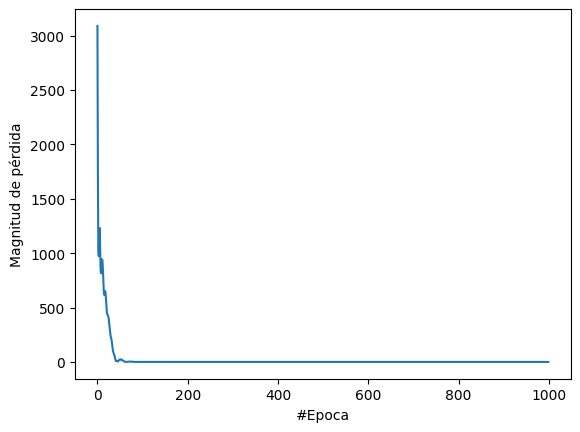

In [21]:
#veamos la función de perdida
import matplotlib.pyplot as plt
plt.xlabel("#Epoca")
plt.ylabel("Magnitud de pérdida")
plt.plot(historial.history["loss"])

In [23]:
#realizando la predicción con una temperatra de C = 200
print("Realizando la Predicción")
resultado = modelo.predict(x=np.array([150]))
print("El resultado es "+str(resultado)+ "farenheit")

Realizando la Predicción
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
El resultado es [[301.6449]]farenheit


In [25]:
#veamos las variables internas del modelo
print("variables internas del modelo")
#print(capa.get_weights())
print(oculta1.get_weights())
print(oculta2.get_weights())
print(salida.get_weights())

variables internas del modelo
[array([[ 0.45757648, -0.3926366 ,  0.16959853]], dtype=float32), array([ 3.9367921, -3.7722259,  3.9360635], dtype=float32)]
[array([[-0.20129448, -0.12124264,  1.3005922 ],
       [-1.0995785 , -0.46359032, -0.79551846],
       [ 0.51316553,  0.06399687,  0.651157  ]], dtype=float32), array([ 2.8855467, -2.4638875,  4.0711346], dtype=float32)]
[array([[ 0.7351179 ],
       [-0.16648118],
       [ 1.4806668 ]], dtype=float32), array([3.875796], dtype=float32)]
